In [ ]:
import requests
import time

import torch
from PIL import Image
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

model_id = "IDEA-Research/grounding-dino-tiny"

processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForZeroShotObjectDetection.from_pretrained(model_id, device_map="auto")

image_url = "http://images.cocodataset.org/val2017/000000039769.jpg"
image = Image.open(requests.get(image_url, stream=True).raw)
# Check for cats and remote controls
text_labels = [["robot","logistics machine"]]

inputs = processor(images=image, text=text_labels, return_tensors="pt").to(model.device)

if model.device.type == "cuda":
    torch.cuda.synchronize(model.device)
start = time.perf_counter()
with torch.no_grad():
    outputs = model(**inputs)
if model.device.type == "cuda":
    torch.cuda.synchronize(model.device)
inference_time = time.perf_counter() - start
print(f"Tempo de inferência: {inference_time * 1000:.2f} ms")

results = processor.post_process_grounded_object_detection(
    outputs,
    inputs.input_ids,
    threshold=0.4,
    text_threshold=0.3,
    target_sizes=[image.size[::-1]]
)

# Retrieve the first image result
result = results[0]
for box, score, labels in zip(result["boxes"], result["scores"], result["labels"]):
    box = [round(x, 2) for x in box.tolist()]
    print(f"Detected {labels} with confidence {round(score.item(), 3)} at location {box}")


/home/eduardo/miniconda3/envs/sam3/lib/python3.12/site-packages/transformers/models/grounding_dino/processing_grounding_dino.py:89: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


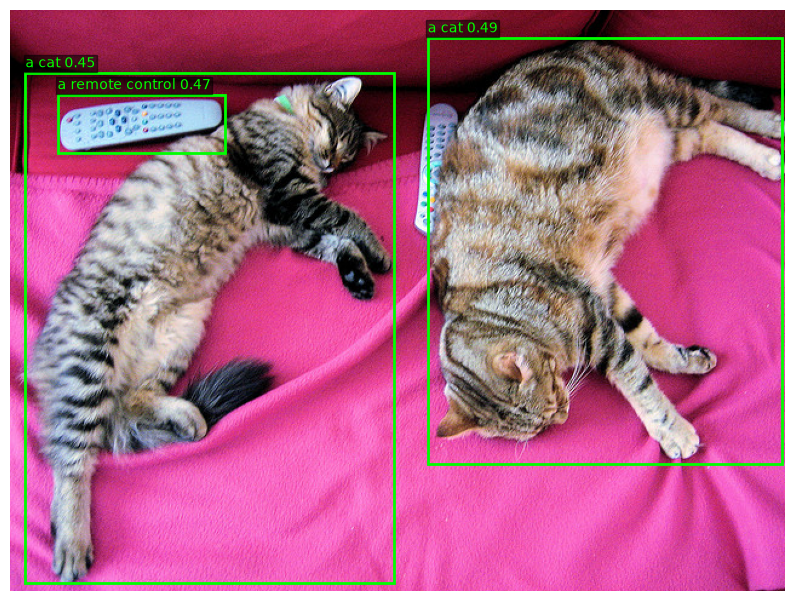

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(1, figsize=(10, 8))
ax.imshow(image)

for box, score, label in zip(result["boxes"], result["scores"], result["labels"]):
    x0, y0, x1, y1 = box.tolist()
    w, h = x1 - x0, y1 - y0
    rect = patches.Rectangle((x0, y0), w, h, linewidth=2, edgecolor="lime", facecolor="none")
    ax.add_patch(rect)
    ax.text(x0, y0 - 5, f"{label} {score:.2f}", color="lime", fontsize=10,
             bbox=dict(facecolor="black", alpha=0.5, pad=1))

ax.axis("off")
plt.show()


## Detecção em vídeo

Lê um vídeo frame a frame, roda o Grounding DINO em cada frame (ou a cada N frames, para acelerar) e grava um novo vídeo com as boxes desenhadas.

In [ ]:
import cv2
import numpy as np
import time
from PIL import Image

video_path = "../lab_fml.mp4"       # caminho do vídeo de entrada
output_path = "lab_fml_boxes.mp4"   # caminho do vídeo de saída (mesma pasta do notebook)
text_labels = [["robot", "logistics machine"]]  # mesmos labels usados na célula de imagem
threshold = 0.4
text_threshold = 0.3
frame_skip = 1  # processa todos os frames

box_color = (0, 255, 0)  # BGR (OpenCV)

# --- Setup multi-GPU: uma réplica do modelo em cada device disponível (até 2) ---
n_gpus = torch.cuda.device_count()
if n_gpus >= 2:
    devices = ["cuda:0", "cuda:1"]
elif n_gpus == 1:
    devices = ["cuda:0"]
    print("Aviso: apenas 1 GPU disponível, rodando em device único.")
else:
    devices = ["cpu"]
    print("Aviso: nenhuma GPU disponível, rodando em CPU.")

print(f"Devices em uso: {devices}")

models = {}
for dev in devices:
    m = AutoModelForZeroShotObjectDetection.from_pretrained(model_id).to(dev)
    m.eval()
    models[dev] = m

inference_times = {dev: [] for dev in devices}  # tempo (s) do forward pass, por device


def draw_boxes_cv2(frame_bgr, boxes, scores, labels):
    for box, score, label in zip(boxes, scores, labels):
        x0, y0, x1, y1 = [int(round(v)) for v in box.tolist()]
        cv2.rectangle(frame_bgr, (x0, y0), (x1, y1), box_color, 2)
        text = f"{label} {score:.2f}"
        (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(frame_bgr, (x0, max(0, y0 - th - 6)), (x0 + tw + 4, y0), box_color, -1)
        cv2.putText(frame_bgr, text, (x0 + 2, max(0, y0 - 4)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
    return frame_bgr


def detect_frame(frame_bgr, device):
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    pil_image = Image.fromarray(frame_rgb)

    inputs = processor(images=pil_image, text=text_labels, return_tensors="pt").to(device)

    if device.startswith("cuda"):
        torch.cuda.synchronize(device)
    start = time.perf_counter()
    with torch.no_grad():
        outputs = models[device](**inputs)
    if device.startswith("cuda"):
        torch.cuda.synchronize(device)
    inference_times[device].append(time.perf_counter() - start)

    results = processor.post_process_grounded_object_detection(
        outputs,
        inputs.input_ids,
        threshold=threshold,
        text_threshold=text_threshold,
        target_sizes=[pil_image.size[::-1]],
    )
    result = results[0]
    return draw_boxes_cv2(frame_bgr, result["boxes"], result["scores"], result["labels"])


In [ ]:
from concurrent.futures import ThreadPoolExecutor

cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise RuntimeError(f"Não foi possível abrir o vídeo: {video_path}")

fps = cap.get(cv2.CAP_PROP_FPS) or 25
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

frame_idx = 0
batch_size = len(devices)  # 1 frame por device, processados em paralelo
pipeline_start = time.perf_counter()

with ThreadPoolExecutor(max_workers=batch_size) as executor:
    while True:
        batch = []
        for _ in range(batch_size):
            ret, frame_bgr = cap.read()
            if not ret:
                break
            batch.append(frame_bgr)
        if not batch:
            break

        futures = [
            executor.submit(detect_frame, frame_bgr, devices[i % len(devices)])
            for i, frame_bgr in enumerate(batch)
        ]
        for future in futures:
            writer.write(future.result())

        frame_idx += len(batch)
        if frame_idx % 30 < batch_size:
            print(f"Processado {frame_idx}/{total_frames} frames")

cap.release()
writer.release()
pipeline_time = time.perf_counter() - pipeline_start
print(f"Vídeo salvo em: {output_path}")

print("\n--- Tempo de inferência (forward pass) ---")
all_times = []
for dev, times in inference_times.items():
    if times:
        arr = np.array(times)
        all_times.extend(times)
        print(f"{dev}: {len(arr)} frames | média {arr.mean() * 1000:.2f} ms | "
              f"min {arr.min() * 1000:.2f} ms | max {arr.max() * 1000:.2f} ms")

if all_times:
    arr = np.array(all_times)
    print(f"Geral: {len(arr)} frames | média {arr.mean() * 1000:.2f} ms/frame | "
          f"throughput só de inferência: {1 / arr.mean():.2f} FPS")

print(f"\nTempo total do pipeline (leitura + inferência + desenho + escrita): "
      f"{pipeline_time:.2f} s | {frame_idx / pipeline_time:.2f} FPS efetivo")
